<a href="https://colab.research.google.com/github/yusufyilmaz-data/konut-fiyat-analizi/blob/main/konut_fiyat_analizi_adl%C4%B1_not_defterinin_kopyas%C4%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("Merhaba, başlıyoruz")

Merhaba, başlıyoruz


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
print("Araçlar hazır")

Araçlar hazır


In [ ]:
from google.colab import userdata
anahtar = userdata.get("EVDS_KEY")
print("Anahtar uzunluğu:", len(anahtar))

Anahtar uzunluğu: 10


In [ ]:
import requests

url = ("https://evds2.tcmb.gov.tr/service/evds/"
       "series=TP.KFE.TR&startDate=01-01-2010&endDate=01-11-2026&type=json")
yanit = requests.get(url, headers={"key": anahtar})

print("Durum kodu:", yanit.status_code)
print(yanit.text[:300])

Durum kodu: 200
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <link rel="icon" href="/assets/images/favicon-BIeG2SoQ.ico" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
<!--      <meta name="viewport" content="width=device-width, initial-scale=1.0, maxim


In [ ]:
!pip install tcmb -q

In [ ]:
import tcmb

istemci = tcmb.Client(
    api_key=anahtar,
    base_url="https://evds3.tcmb.gov.tr/igmevdsms-dis/"
)
veri = istemci.read(series="TP.KFE.TR", start_date="01-01-2010")
print(veri.head())

            TP_KFE_TR
Tarih                
2010-01-01       4.57
2010-02-01       4.57
2010-03-01       4.58
2010-04-01       4.63
2010-05-01       4.68


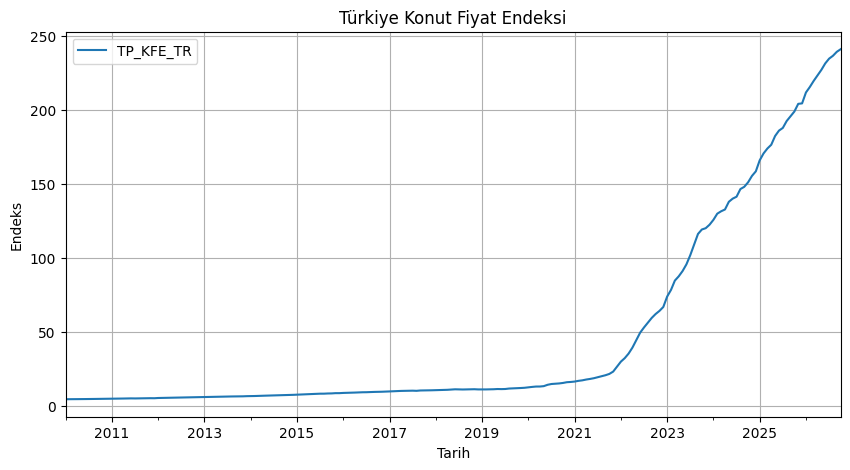

In [ ]:
veri.plot(figsize=(10, 5), title="Türkiye Konut Fiyat Endeksi")
plt.ylabel("Endeks")
plt.grid(True)
plt.show()

In [ ]:
tufe = istemci.read(series="TP.FG.J0", start_date="01-01-2010")

df = veri.join(tufe, how="inner")
df.columns = ["konut", "tufe"]
df["reel"] = df["konut"] / df["tufe"] * 100

print(df.tail())


             konut     tufe      reel
Tarih                                
2025-09-01  195.66  3367.22  5.810728
2025-10-01  198.87  3453.09  5.759190
2025-11-01  204.04  3482.96  5.858236
2025-12-01  204.36  3513.87  5.815810
2026-01-01  211.73  3683.83  5.747551


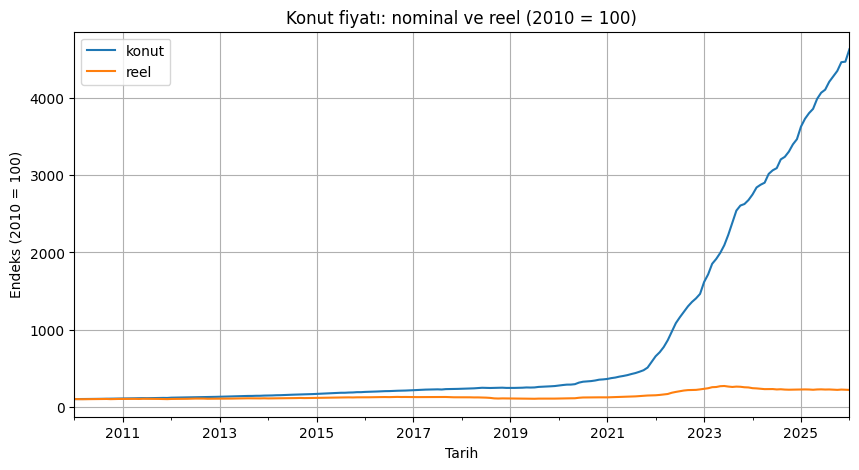

In [ ]:
norm = df / df.iloc[0] * 100

norm[["konut", "reel"]].plot(figsize=(10, 5),
    title="Konut fiyatı: nominal ve reel (2010 = 100)")
plt.ylabel("Endeks (2010 = 100)")
plt.grid(True)
plt.show()

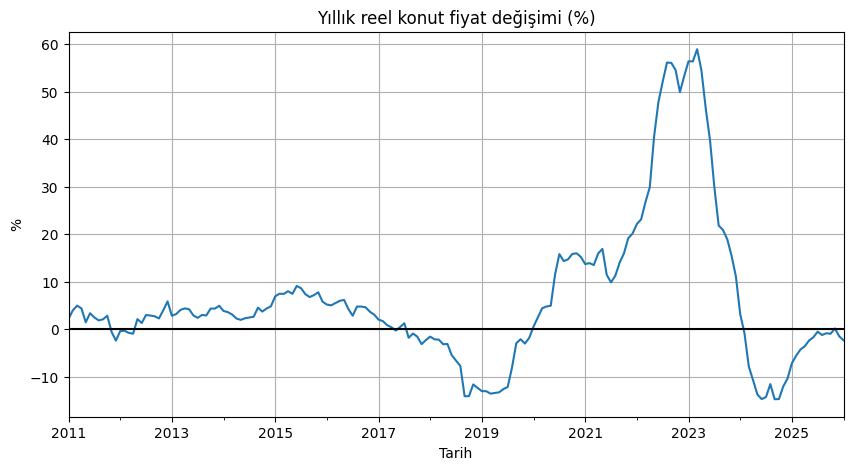

In [ ]:
yillik = df["reel"].pct_change(12) * 100

yillik.dropna().plot(figsize=(10, 5),
    title="Yıllık reel konut fiyat değişimi (%)")
plt.axhline(0, color="black")
plt.ylabel("%")
plt.grid(True)
plt.show()

In [ ]:
bolgeler = {"İstanbul": "TP.KFE.TR10",
            "Ankara": "TP.KFE.TR51",
            "İzmir": "TP.KFE.TR31"}

tablo = pd.DataFrame()
for ad, kod in bolgeler.items():
    tablo[ad] = istemci.read(series=kod, start_date="01-01-2010").iloc[:, 0]

print(tablo.tail())

            İstanbul  Ankara   İzmir
Tarih                               
2026-06-01    216.62  255.69  225.16
2026-07-01    222.40  261.03  223.47
2026-08-01    226.36  264.82  229.14
2026-09-01    230.51  264.90  231.28
2026-10-01    233.13  269.18  229.87


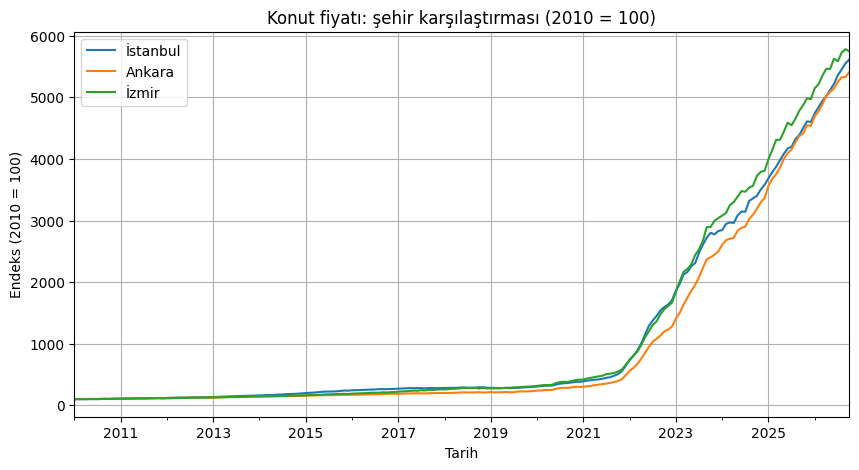

            İstanbul  Ankara   İzmir
Tarih                               
2026-10-01    5618.0  5416.0  5747.0


In [ ]:
norm_sehir = tablo / tablo.iloc[0] * 100

norm_sehir.plot(figsize=(10, 5),
    title="Konut fiyatı: şehir karşılaştırması (2010 = 100)")
plt.ylabel("Endeks (2010 = 100)")
plt.grid(True)
plt.show()

print(norm_sehir.tail(1).round(0))

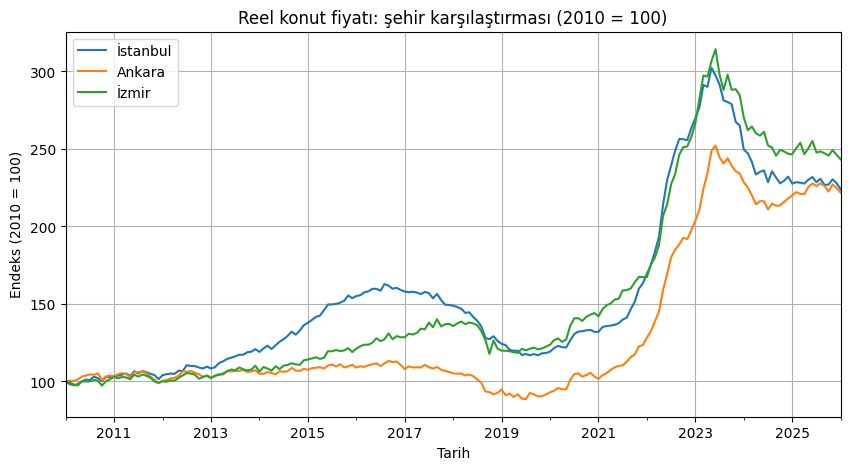

            İstanbul  Ankara  İzmir
Tarih                              
2026-01-01     224.0   222.0  243.0


In [ ]:
birlesik = tablo.join(tufe, how="inner")
enflasyon = birlesik.iloc[:, -1]

reel_sehir = birlesik[["İstanbul", "Ankara", "İzmir"]].div(enflasyon, axis=0) * 100
reel_norm = reel_sehir / reel_sehir.iloc[0] * 100

reel_norm.plot(figsize=(10, 5),
    title="Reel konut fiyatı: şehir karşılaştırması (2010 = 100)")
plt.ylabel("Endeks (2010 = 100)")
plt.grid(True)
plt.show()

print(reel_norm.tail(1).round(0))